# Odszumianie (zadanie 2.2)


**Parametry i założenia:**
* **dane:** obrazy 256x256 z DIV2K (`01_data_preparation.ipynb`)
* **szum gaussowski:**  sigma = 0.01 i 0.03 (obrazy w zakresie 0-1)
* **metoda bazowa:** `denoise_bilateral` z skimage (parametry dobrane na zbiorze walidacyjnym)
* **nasza metoda:** U-Net (`models.py`), osobny model dla każdego sigma
* **metryki:** SNE, PSNR, SSIM, LPIPS

## 1. Środowisko Google Colab

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install lpips torchmetrics -q

In [4]:
import os, sys, json, shutil
sys.path.append('/content/drive/MyDrive/sigk')   # folder with our .py files

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader
import lpips

from denoise_data import DenoiseDataset
from baselines import bilateral_denoise
from metrics import all_metrics, psnr
from models import UNet

device = 'cuda' if torch.cuda.is_available() else 'cpu'
drive_dir = '/content/drive/MyDrive/sigk'
lpips_model = lpips.LPIPS(net='alex').to(device)   # network used for the LPIPS metric
print(device)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 185MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
cuda


Dane kopiujemy z Dysku na lokalny dysk Colaba

In [5]:
local_dir = '/content/data256_local'
if not os.path.exists(local_dir):
    shutil.copytree(f'{drive_dir}/data256', local_dir)
data_dir = local_dir

for folder in ['train', 'val', 'test']:
    print(folder, len(os.listdir(f'{data_dir}/{folder}')))

train 720
val 80
test 100


## 2. Szum gaussowski

Do obrazów dodajemy szum gaussowski o odchyleniu standardowym **σ = 0.01** oraz **σ = 0.03**. Obrazy są znormalizowane do przedziału <0, 1> (wartości pikseli podzielone przez 255).

Do każdego piksela dodawana jest wartość wylosowana z rozkładu normalnego N(0, σ²), a wynik jest obcinany do przedziału <0, 1>. Szum generuje funkcja `add_gaussian_noise` z pliku `denoise_data.py`.
* **zbiór treningowy:** szum jest losowany od nowa za każdym razem, więc sieć nie widzi dwa razy tego samego szumu,
* **zbiory walidacyjny i testowy:** szum ma stałe ziarno (osobne dla każdego obrazu), dzięki czemu wyniki są powtarzalne, a wszystkie metody są oceniane na tych samych zaszumionych obrazach.

Poniżej widać obraz czysty oraz ten sam obraz zaszumiony dla σ = 0.01 i σ = 0.03 (zbiór testowy).

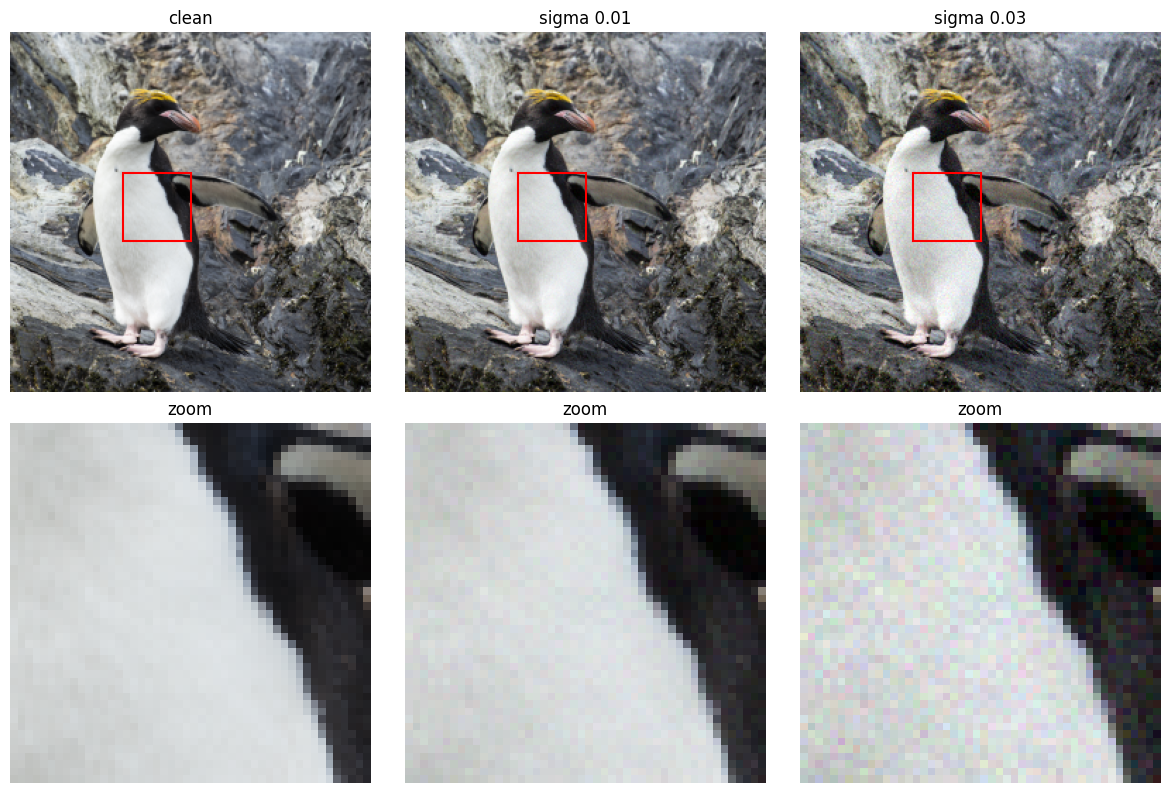

In [10]:
x, y, size = 80, 100, 48          # left edge, top edge, size of the zoomed fragment

images = []
for sigma in [0.01, 0.03]:
    ds = DenoiseDataset(f'{data_dir}/test', sigma=sigma, fixed_noise=True)
    noisy, clean = ds[0]
    images.append(noisy)
images = [clean] + images
titles = ['clean', 'sigma 0.01', 'sigma 0.03']

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i in range(3):
    img = images[i].permute(1, 2, 0)
    axes[0, i].imshow(img)
    axes[0, i].add_patch(Rectangle((x, y), size, size, edgecolor='red', facecolor='none', linewidth=1.5))
    axes[0, i].set_title(titles[i])
    axes[1, i].imshow(img[y:y + size, x:x + size], interpolation='nearest')
    axes[1, i].set_title('zoom')

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{drive_dir}/denoise_noise_preview.png', dpi=150)
plt.show()

## 3. Metoda bazowa: dobór parametrów bilaterala
Domyślne parametry `denoise_bilateral` mocno rozmywają obraz (PSNR ok. 20 dB), więc szukamy lepszych
na **zbiorze walidacyjnym** (10 obrazów), osobno dla każdego sigma. Wybieramy kombinację z największym PSNR.
Zbioru testowego do tego nie używamy.

In [9]:
bilateral_params = {}   # sigma -> (sigma_color, sigma_spatial)

for sigma in [0.01, 0.03]:
    val_ds = DenoiseDataset(f'{data_dir}/val', sigma=sigma, fixed_noise=True)
    noisy, clean = next(iter(DataLoader(val_ds, batch_size=10, shuffle=False)))
    print('sigma', sigma, '| noisy input PSNR:', round(psnr(noisy, clean).mean().item(), 2))   #PSNR of noisy images as a reference

    best_psnr = -1
    for sc in [0.003, 0.005, 0.01, 0.02]:     #sc: how much the colours of the pixels can vary for the filter to still average them out
        for ss in [2, 3, 4]:                  #ss: how far (in pixels) does the averaging extend
            out = bilateral_denoise(noisy, sigma_color=sc, sigma_spatial=ss)
            p = psnr(out, clean).mean().item()      # PSNR of the denoised images relative to the original images, averaged over 10 pictures
            print(f'  sigma_color={sc}, sigma_spatial={ss}: {p:.2f}')
            if p > best_psnr:
                best_psnr = p
                bilateral_params[sigma] = (sc, ss)
    print('  -> best:', bilateral_params[sigma], round(best_psnr, 2))

sigma 0.01 | noisy input PSNR: 40.03
  sigma_color=0.003, sigma_spatial=2: 41.24
  sigma_color=0.003, sigma_spatial=3: 41.37
  sigma_color=0.003, sigma_spatial=4: 41.41
  sigma_color=0.005, sigma_spatial=2: 41.21
  sigma_color=0.005, sigma_spatial=3: 41.52
  sigma_color=0.005, sigma_spatial=4: 41.61
  sigma_color=0.01, sigma_spatial=2: 39.08
  sigma_color=0.01, sigma_spatial=3: 39.47
  sigma_color=0.01, sigma_spatial=4: 39.53
  sigma_color=0.02, sigma_spatial=2: 35.36
  sigma_color=0.02, sigma_spatial=3: 35.56
  sigma_color=0.02, sigma_spatial=4: 35.49
  -> best: (0.005, 4) 41.61
sigma 0.03 | noisy input PSNR: 30.53
  sigma_color=0.003, sigma_spatial=2: 30.85
  sigma_color=0.003, sigma_spatial=3: 30.87
  sigma_color=0.003, sigma_spatial=4: 30.89
  sigma_color=0.005, sigma_spatial=2: 31.60
  sigma_color=0.005, sigma_spatial=3: 31.62
  sigma_color=0.005, sigma_spatial=4: 31.62
  sigma_color=0.01, sigma_spatial=2: 33.43
  sigma_color=0.01, sigma_spatial=3: 33.51
  sigma_color=0.01, sigma_

## 4. Model: U-Net
Sprawdzamy, czy sieć przyjmuje obraz 256x256 i zwraca obraz o tym samym rozmiarze.

Architekturę sieci definiuje plik `models.py` (klasa `UNet`, `base = 32`). Sieć przyjmuje obraz zaszumiony 3 × 256 × 256 i zwraca obraz o tym samym rozmiarze, a jej wyjście to wejście powiększone o wyuczoną korektę (uczenie rezydualne).

Poniższa komórka sprawdza, czy rozmiar wyjścia zgadza się z rozmiarem wejścia, i wypisuje liczbę parametrów (1 925 667).

In [13]:
model = UNet().to(device)
x = torch.randn(2, 3, 256, 256).to(device)
print('output shape:', tuple(model(x).shape))
print('parameters:', sum(p.numel() for p in model.parameters()))

output shape: (2, 3, 256, 256)
parameters: 1925667


## 5. Trening

Osobny model dla każdego σ. Funkcja straty: L1 + 0,05·LPIPS, optymalizator: Adam, 100 epok.
W każdej epoce na zbiorze treningowym szum jest losowany od nowa. Po każdej epoce liczymy PSNR na zbiorze walidacyjnym i zapisujemy na Dysk najlepszy model oraz historię uczenia.
Jeśli model dla danego σ już istnieje na Dysku, trening jest pomijany.

In [6]:
torch.manual_seed(0)    # fixed seed, so the run can be repeated

epochs = 100
lpips_weight = 0.05     # weight of the LPIPS part of the loss (0 = only L1)

for p in lpips_model.parameters():
    p.requires_grad_(False)     # LPIPS is only a measuring tool here, we do not train it

for sigma in [0.03, 0.01]:
    save_path = f'{drive_dir}/unet_denoise_{sigma}.pt'
    history_path = f'{drive_dir}/history_denoise_{sigma}.json'
    if os.path.exists(save_path):
        print(f'sigma {sigma}: model already exists, skipping training')
        continue

    model = UNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)   # learning rate slowly goes down
    loss_fn = torch.nn.L1Loss()

    train_ds = DenoiseDataset(f'{data_dir}/train', sigma=sigma, fixed_noise=False)   # new random noise every time
    train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
    val_ds = DenoiseDataset(f'{data_dir}/val', sigma=sigma, fixed_noise=True)
    val_dl = DataLoader(val_ds, batch_size=16, shuffle=False)

    best_val = 0
    history = []
    print('training for sigma', sigma)
    for epoch in range(1, epochs + 1):
        # training
        model.train()
        total_loss = 0
        for noisy, clean in train_dl:
            noisy, clean = noisy.to(device), clean.to(device)
            pred = model(noisy)
            loss = loss_fn(pred, clean)
            if lpips_weight > 0:
                loss = loss + lpips_weight * lpips_model(pred * 2 - 1, clean * 2 - 1).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        scheduler.step()

        # validation
        model.eval()
        val_values = []
        with torch.no_grad():
            for noisy, clean in val_dl:
                pred = model(noisy.to(device)).clamp(0, 1)
                val_values += psnr(pred, clean.to(device)).cpu().tolist()
        val_psnr = float(np.mean(val_values))

        history.append({'epoch': epoch, 'loss': total_loss / len(train_dl), 'val_psnr': val_psnr})
        print(f'  epoch {epoch}: loss {history[-1]["loss"]:.4f} | val PSNR {val_psnr:.2f}')

        # save the best model and the history to Drive
        if val_psnr > best_val:
            best_val = val_psnr
            torch.save(model.state_dict(), save_path)
        json.dump(history, open(history_path, 'w'))

training for sigma 0.03
  epoch 1: loss 0.0490 | val PSNR 30.30
  epoch 2: loss 0.0277 | val PSNR 30.45
  epoch 3: loss 0.0272 | val PSNR 30.55
  epoch 4: loss 0.0268 | val PSNR 30.69
  epoch 5: loss 0.0262 | val PSNR 30.82
  epoch 6: loss 0.0254 | val PSNR 31.11
  epoch 7: loss 0.0242 | val PSNR 31.54
  epoch 8: loss 0.0226 | val PSNR 32.03
  epoch 9: loss 0.0211 | val PSNR 32.55
  epoch 10: loss 0.0197 | val PSNR 33.08
  epoch 11: loss 0.0185 | val PSNR 33.67
  epoch 12: loss 0.0172 | val PSNR 34.08
  epoch 13: loss 0.0165 | val PSNR 34.32
  epoch 14: loss 0.0168 | val PSNR 34.37
  epoch 15: loss 0.0160 | val PSNR 34.39
  epoch 16: loss 0.0158 | val PSNR 34.58
  epoch 17: loss 0.0157 | val PSNR 34.63
  epoch 18: loss 0.0154 | val PSNR 34.69
  epoch 19: loss 0.0154 | val PSNR 34.72
  epoch 20: loss 0.0154 | val PSNR 34.74
  epoch 21: loss 0.0152 | val PSNR 34.79
  epoch 22: loss 0.0152 | val PSNR 34.80
  epoch 23: loss 0.0150 | val PSNR 34.87
  epoch 24: loss 0.0150 | val PSNR 34.88
 

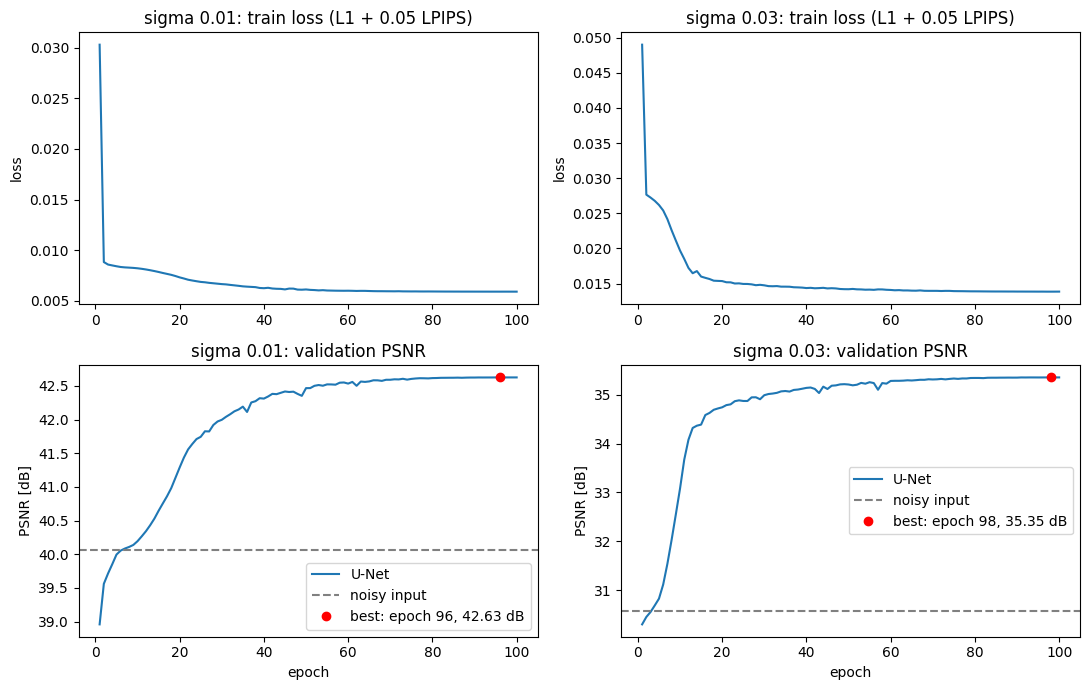

In [7]:
def val_noisy_psnr(sigma):
    ds = DenoiseDataset(f'{data_dir}/val', sigma=sigma, fixed_noise=True)
    values = []
    for noisy, clean in DataLoader(ds, batch_size=16):
        values += psnr(noisy, clean).tolist()
    return float(np.mean(values))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, sigma in enumerate([0.01, 0.03]):
    h = json.load(open(f'{drive_dir}/history_denoise_{sigma}.json'))
    epochs_list = [e['epoch'] for e in h]
    loss = [e['loss'] for e in h]
    val = [e['val_psnr'] for e in h]
    best = int(np.argmax(val))

    axes[0, col].plot(epochs_list, loss)
    axes[0, col].set_title(f'sigma {sigma}: train loss (L1 + 0.05 LPIPS)')
    axes[0, col].set_ylabel('loss')

    axes[1, col].plot(epochs_list, val, label='U-Net')
    axes[1, col].axhline(val_noisy_psnr(sigma), color='gray', linestyle='--', label='noisy input')
    axes[1, col].plot(epochs_list[best], val[best], 'ro', label=f'best: epoch {best + 1}, {val[best]:.2f} dB')
    axes[1, col].set_title(f'sigma {sigma}: validation PSNR')
    axes[1, col].set_ylabel('PSNR [dB]')
    axes[1, col].set_xlabel('epoch')
    axes[1, col].legend()

plt.tight_layout()
plt.savefig(f'{drive_dir}/denoise_training_curves.png', dpi=150)
plt.show()

Górny rząd pokazuje stratę treningową, dolny PSNR na zbiorze walidacyjnym w kolejnych epokach. Linia przerywana to PSNR obrazu zaszumionego (bez przetwarzania), a czerwona kropka oznacza najlepszą epokę, z której zapisano model.

## 6. Ewaluacja na zbiorze testowym

Porównujemy trzy warianty na **całym zbiorze testowym (100 obrazów)**, osobno dla każdego σ:
* **noisy input** – obraz zaszumiony bez przetwarzania (punkt odniesienia),
* **bilateral denoise** – metoda bazowa (`denoise_bilateral`) z parametrami dobranymi na zbiorze walidacyjnym,
* **unet denoise** – nasza sieć (najlepszy model zapisany podczas treningu).

Wszystkie trzy warianty są oceniane na tych samych obrazach z tym samym szumem (stałe ziarno), więc porównanie jest uczciwe. Dla każdego obrazu liczymy cztery metryki (SNE, PSNR, SSIM, LPIPS), po obcięciu wyniku do przedziału <0, 1>. Wartości dla pojedynczych obrazów zapisujemy w słowniku `scores`, a uśredniamy je w sekcji 7.

In [10]:
def load_unet(sigma):
    m = UNet().to(device)
    m.load_state_dict(torch.load(f'{drive_dir}/unet_denoise_{sigma}.pt', map_location=device))
    m.eval()
    return m

scores = {}

for sigma in [0.01, 0.03]:
    sc, ss = bilateral_params[sigma]
    model = load_unet(sigma)

    test_ds = DenoiseDataset(f'{data_dir}/test', sigma=sigma, fixed_noise=True)
    test_dl = DataLoader(test_ds, batch_size=10, shuffle=False)

    with torch.no_grad():
        for noisy, clean in test_dl:
            outputs = {
                f'noisy input sigma {sigma}': noisy,
                f'bilateral denoise sigma {sigma}': bilateral_denoise(noisy, sigma_color=sc, sigma_spatial=ss),
                f'unet denoise sigma {sigma}': model(noisy.to(device)).cpu(),
            }
            for name, pred in outputs.items():
                m = all_metrics(pred.clamp(0, 1).to(device), clean.to(device), lpips_model)
                if name not in scores:
                    scores[name] = {k: [] for k in m}
                for k in m:
                    scores[name][k] += m[k].cpu().tolist()

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


## 7. Tabela wyników

Średnie wartości metryk na całym zbiorze testowym (100 obrazów), osobno dla σ = 0.01 i σ = 0.03. Dla każdego σ porównujemy trzy warianty: obraz zaszumiony bez przetwarzania (`noisy input`, punkt odniesienia), metodę bazową (`bilateral denoise`) i naszą sieć (`unet denoise`).

Kierunek poprawy: **PSNR i SSIM – wyżej = lepiej, SNE i LPIPS – niżej = lepiej.**

Uwaga: LPIPS był składnikiem funkcji straty podczas treningu, więc porównanie w tej metryce jest dla sieci korzystniejsze. Wyniki pochodzą z jednego przebiegu treningu.

In [11]:
table = pd.DataFrame({name: {k: np.mean(v) for k, v in s.items()} for name, s in scores.items()}).T
table.to_csv(f'{drive_dir}/results_denoising.csv')
table.round(4)

,SNE,PSNR,SSIM,LPIPS
noisy input sigma 0.01,19.4010,40.0599,0.9706,0.0084
bilateral denoise sigma 0.01,15.7769,41.1054,0.9860,0.0055
unet denoise sigma 0.01,11.2385,42.5731,0.9899,0.0021
noisy input sigma 0.03,171.9150,30.5870,0.8270,0.0685
bilateral denoise sigma 0.03,100.1835,33.1078,0.9357,0.0411
unet denoise sigma 0.03,62.1605,35.2300,0.9596,0.0139


### 8. Wizualizacja i analiza jakościowa wyników ($\sigma = 0.03$)

Ta sekcja służy do weryfikacji wizualnej oraz ilościowej jakości odszumiania dla wybranego obrazu testowego przy poziomie szumu $\sigma = 0.03$.

**Układ wizualizacji (siatka $3 \times 4$):**
* **Kolumny:** Przedstawiają cztery warianty tego samego obrazu:
  1. `noisy` – obraz zdegradowany (wejściowy zaszumiony),
  2. `bilateral` – wynik tradycyjnej metody bazowej (Filtrowanie bilateralne ze zoptymalizowanymi parametrami $\sigma_c, \sigma_s$),
  3. `U-Net` – wynik uzyskany przez wytrenowany model sieci neuronowej w PyTorchu,
  4. `clean` – obraz oryginalny bez szumu (*Ground Truth*).
* **Wiersze 0 i 1 (Zbliżenia / Zgrupowane wycinki):** Dwa wybrane fragmenty o rozmiarze $48 \times 48$ pikseli (`smooth area` – obszar gładki oraz `texture` – tekstura). Pozwalają ocenić zdolność modelu do usuwania szumu w obszarach jednorodnych oraz zachowania ostrości krawędzi i detali.
* **Wiersz 2 (Mapa błędu):** Przedstawia mapę średniego błędu bezwzględnego względem obrazu czystego (`error = (img - clean).abs().mean(dim=0)`). Jaśniejsze piksele oznaczają większą różnicę (większy błąd), natomiast ciemniejsze obszary wskazują na wysoką wierność rekonstrukcji (skala błędu znormalizowana w zakresie $0.0 - 0.1$).

Wygenerowany wykres jest automatycznie zapisywany na dysku jako plik `denoise_zoom.png`.

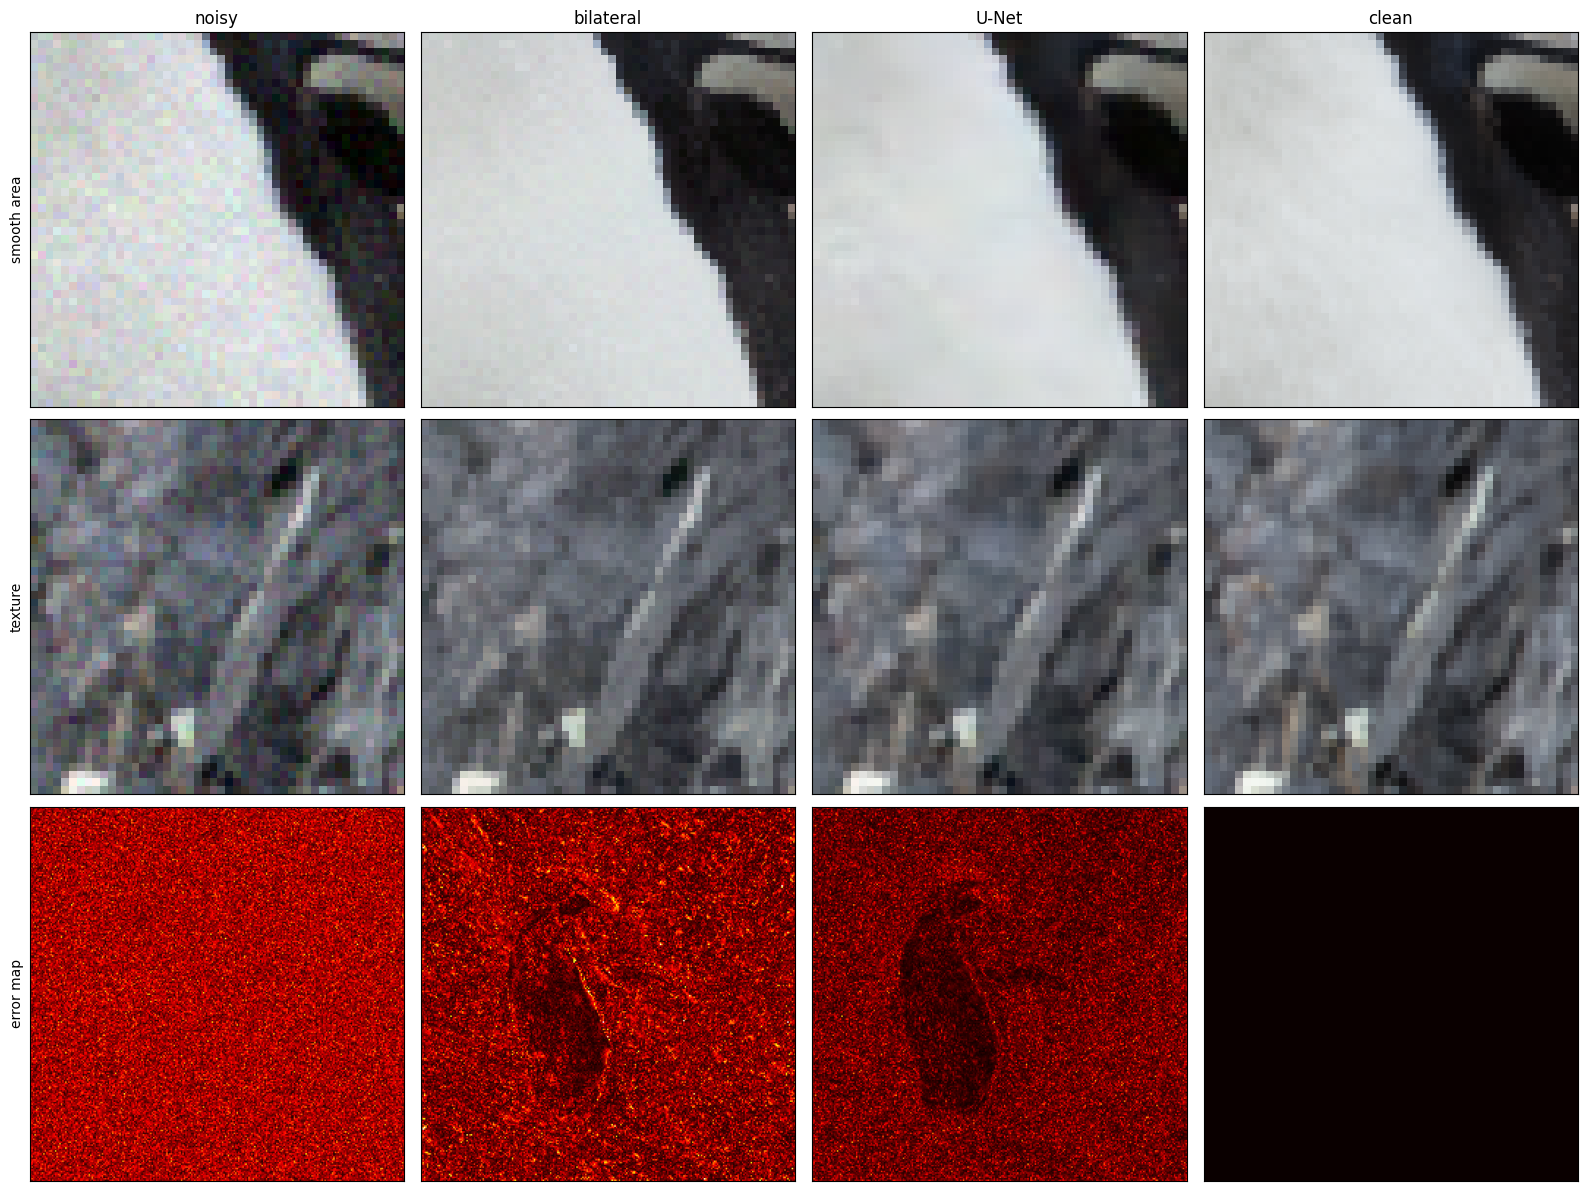

In [17]:
sigma = 0.03
sc, ss = bilateral_params[sigma]
model = load_unet(sigma)

test_ds = DenoiseDataset(f'{data_dir}/test', sigma=sigma, fixed_noise=True)
noisy, clean = test_ds[0]                      # change 0 to see another image
with torch.no_grad():
    unet_out = model(noisy.unsqueeze(0).to(device))[0].cpu()
bilateral_out = bilateral_denoise(noisy.unsqueeze(0), sigma_color=sc, sigma_spatial=ss)[0]

images = [noisy, bilateral_out, unet_out, clean]
titles = ['noisy', 'bilateral', 'U-Net', 'clean']

size = 48
crops = [('smooth area', 100, 80), ('texture', 40, 200)]   # (name, top edge y, left edge x)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for col in range(4):
    img = images[col].clamp(0, 1)

    # rows 1 and 2: zoomed crops
    for row in range(2):
        name, y, x = crops[row]
        crop = img[:, y:y + size, x:x + size]
        axes[row, col].imshow(crop.permute(1, 2, 0), interpolation='nearest')
        axes[row, 0].set_ylabel(name)

    # row 3: error map (brighter = bigger difference from the clean image)
    error = (img - clean).abs().mean(dim=0)
    axes[2, col].imshow(error, cmap='hot', vmin=0, vmax=0.1)
    axes[0, col].set_title(titles[col])
axes[2, 0].set_ylabel('error map')

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig(f'{drive_dir}/denoise_zoom.png', dpi=150)
plt.show()

## 9. Wykres metryk

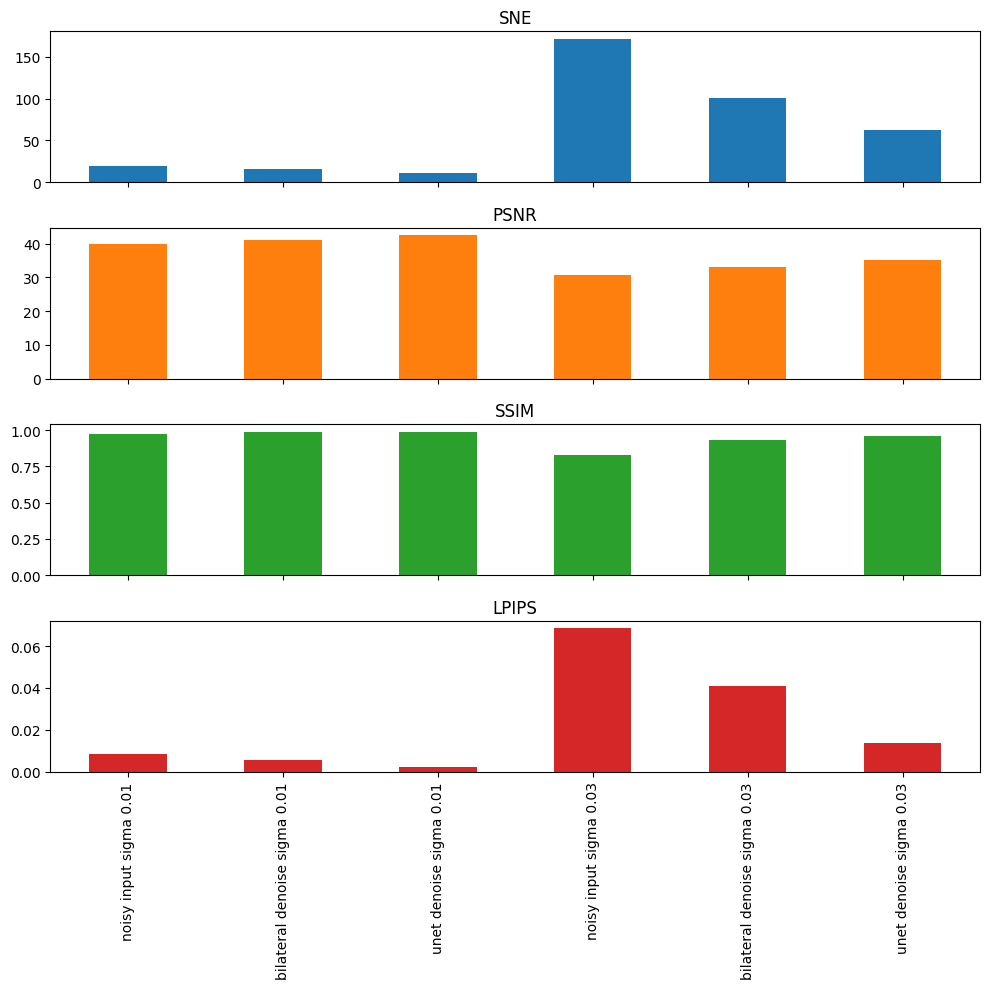

In [18]:
table[['SNE','PSNR', 'SSIM', 'LPIPS']].plot(kind='bar', subplots=True, figsize=(10, 10), legend=False)
plt.tight_layout()
plt.savefig(f'{drive_dir}/denoise_metrics.png', dpi=150)
plt.show()

### 10. Analiza wyników PSNR dla każdego obrazu testowego osobno

W tej sekcji przedstawiono szczegółową analizę rozkładu miary PSNR dla każdego z 100 obrazów testowych ze zbioru DIV2K z osobna, uwzględniając dwa poziomy szumu gaussowskiego ($\sigma = 0.01$ oraz $\sigma = 0.03$).

**Interpretacja wykresów rozrzutu (Scatter Plots):**
* **Oś X:** Wartość PSNR dla obrazu wejściowego zaszumionego (*noisy input [dB]*).
* **Oś Y:** Wartość PSNR uzyskana po procesie odszumiania (*PSNR after denoising [dB]*).
* **Czerwona linia przerywana (`no change`):** Oznacza próg referencyjny, w którym jakość wyjściowa jest równa wejściowej. Punkty znajdujące się **powyżej tej linii** wskazują, że metoda skutecznie poprawiła jakość obrazu.
* **Oznaczenia serii:**
  * Niebieskie punkty (`bilateral`) – tradycyjna metoda bazowa (filtr bilateralny).
  * Pomarańczowe punkty (`U-Net`) – model oparty na sieci neuronowej w PyTorchu.

**Wnioski:** U-Net uzyskuje wyższy PSNR niż filtr bilateralny dla większości obrazów testowych. Dla σ = 0.01 bilateral pogorszył część obrazów względem obrazu zaszumionego (punkty pod linią no change), a U-Net nie pogorszył żadnego.

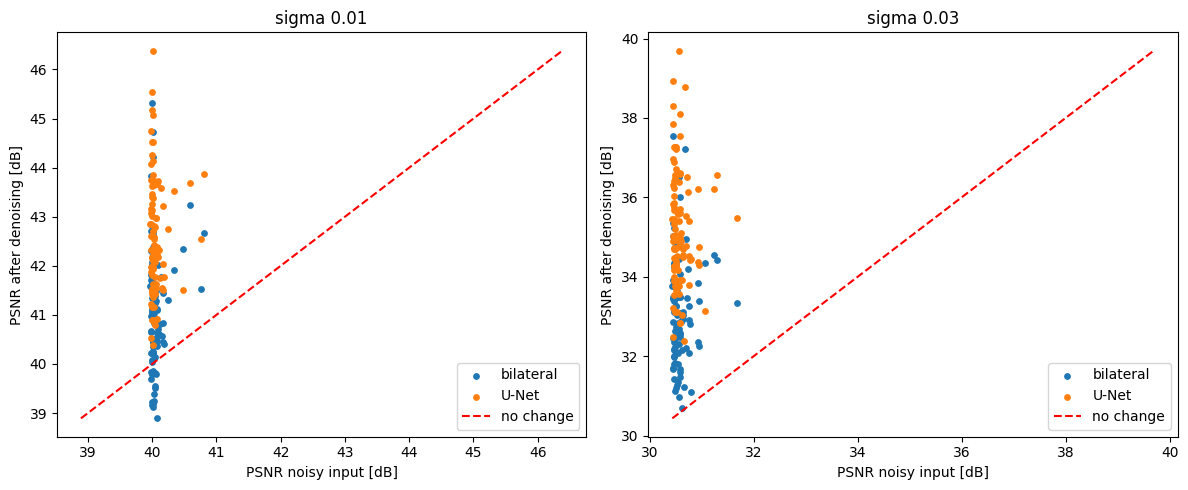

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, sigma in zip(axes, [0.01, 0.03]):
    before = scores[f'noisy input sigma {sigma}']['PSNR']
    bil = scores[f'bilateral denoise sigma {sigma}']['PSNR']
    unet = scores[f'unet denoise sigma {sigma}']['PSNR']
    ax.scatter(before, bil, s=15, label='bilateral')
    ax.scatter(before, unet, s=15, label='U-Net')
    low, high = min(before + bil + unet), max(before + bil + unet)
    ax.plot([low, high], [low, high], 'r--', label='no change')
    ax.set_title(f'sigma {sigma}')
    ax.set_xlabel('PSNR noisy input [dB]')
    ax.set_ylabel('PSNR after denoising [dB]')
    ax.legend()
plt.tight_layout()
plt.savefig(f'{drive_dir}/denoise_per_image.png', dpi=150)
plt.show()